In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
%matplotlib inline
import warnings
warnings.filterwarnings("ignore")

In [2]:
df=pd.read_csv("for_modeling_2.csv")

In [9]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 14510 entries, 0 to 14509
Data columns (total 10 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   Unnamed: 0                   14510 non-null  int64  
 1   domain_token_count           14510 non-null  int64  
 2   executable                   14510 non-null  int64  
 3   NumberofDotsinURL            14510 non-null  int64  
 4   Arguments_LongestWordLength  14510 non-null  int64  
 5   NumberRate_Domain            14510 non-null  float64
 6   NumberRate_FileName          14510 non-null  float64
 7   NumberRate_AfterPath         14510 non-null  float64
 8   Entropy_Domain               14510 non-null  float64
 9   class                        14510 non-null  object 
dtypes: float64(4), int64(5), object(1)
memory usage: 1.1+ MB


In [11]:
df = df.drop(columns=['Unnamed: 0'])

In [13]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 14510 entries, 0 to 14509
Data columns (total 9 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   domain_token_count           14510 non-null  int64  
 1   executable                   14510 non-null  int64  
 2   NumberofDotsinURL            14510 non-null  int64  
 3   Arguments_LongestWordLength  14510 non-null  int64  
 4   NumberRate_Domain            14510 non-null  float64
 5   NumberRate_FileName          14510 non-null  float64
 6   NumberRate_AfterPath         14510 non-null  float64
 7   Entropy_Domain               14510 non-null  float64
 8   class                        14510 non-null  object 
dtypes: float64(4), int64(4), object(1)
memory usage: 1020.4+ KB


In [15]:
df['class'].value_counts()

class
Defacement    5757
spam          4914
malware       3024
phishing       815
Name: count, dtype: int64

In [19]:
# (행, 열) 확인
df.shape

(14510, 9)

In [21]:
# 결측치 확인
df.isnull().sum()

domain_token_count             0
executable                     0
NumberofDotsinURL              0
Arguments_LongestWordLength    0
NumberRate_Domain              0
NumberRate_FileName            0
NumberRate_AfterPath           0
Entropy_Domain                 0
class                          0
dtype: int64

In [23]:
# 기초 통계량 확인
df.describe()

,domain_token_count,executable,NumberofDotsinURL,Arguments_LongestWordLength,NumberRate_Domain,NumberRate_FileName,NumberRate_AfterPath,Entropy_Domain
count,14510.000000,14510.0,14510.000000,14510.000000,14510.000000,14510.000000,14510.000000,14510.000000
mean,3.080427,0.0,3.330324,5.809304,0.048535,0.156794,0.187007,0.827540
std,0.759217,0.0,1.114376,6.038104,0.123929,0.139459,0.165908,0.056686
min,2.000000,0.0,1.000000,0.000000,0.000000,0.000000,0.000000,0.667000
25%,3.000000,0.0,3.000000,0.000000,0.000000,0.056000,0.065000,0.788000
50%,3.000000,0.0,3.000000,5.000000,0.000000,0.111000,0.127000,0.829000
75%,3.000000,0.0,4.000000,11.000000,0.000000,0.226000,0.320000,0.863000
max,8.000000,0.0,17.000000,33.000000,0.733000,1.000000,1.000000,1.000000


class 분포 확인


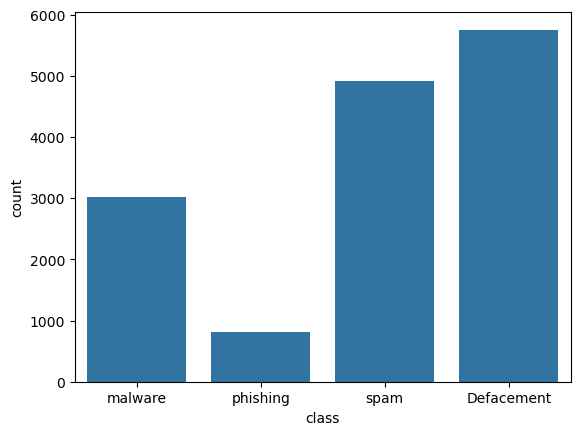

In [25]:
# 클래스 분포 확인
sns.countplot(x = df['class'], data = df)
print("class 분포 확인")

In [27]:
# 한글 폰트 설정
from matplotlib import font_manager, rc

font_path = "C:/Windows/Fonts/malgun.ttf"
font = font_manager.FontProperties(fname=font_path).get_name()
rc('font', family=font)
plt.rcParams['axes.unicode_minus'] = False  # 마이너스 깨짐 방지

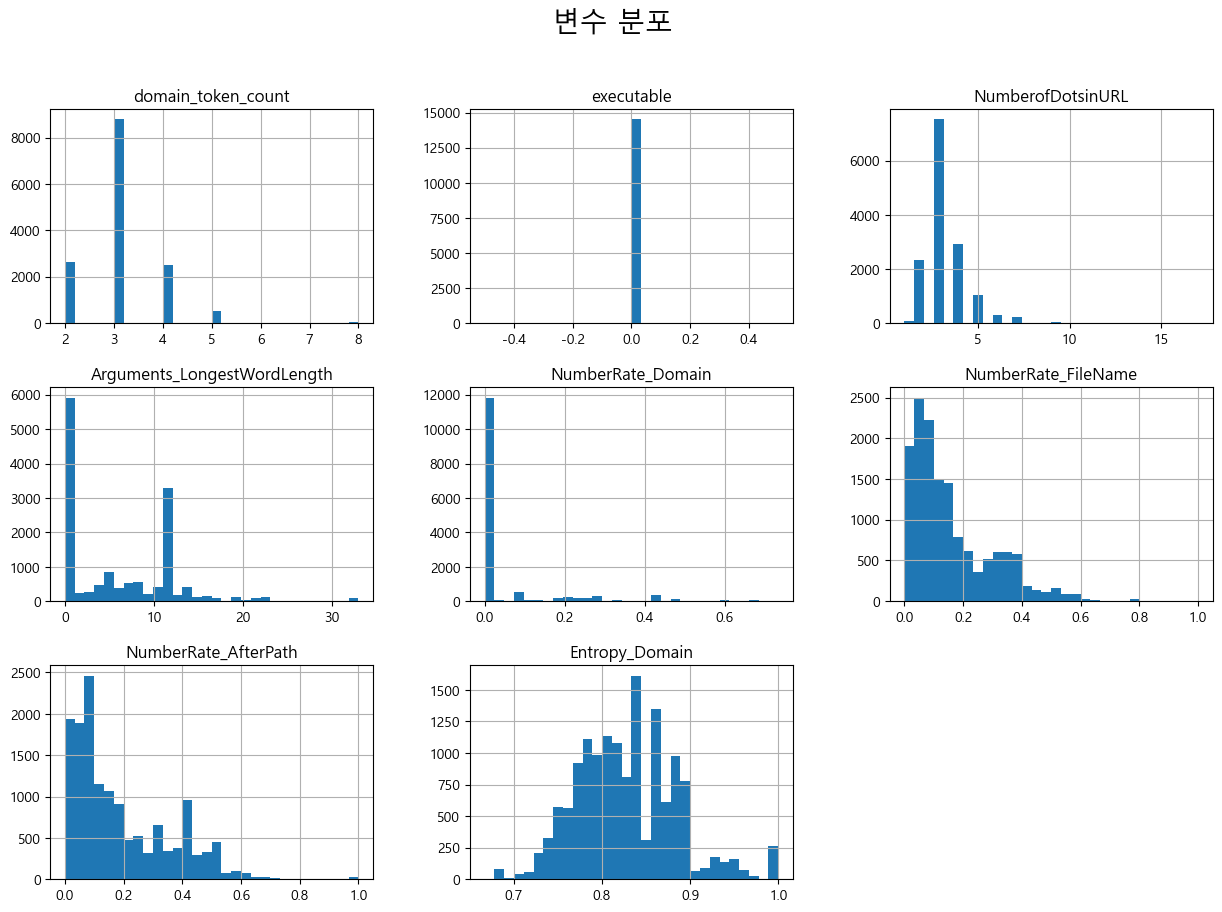

In [29]:
# 주요 feature 분포 확인
df.hist(bins=30, figsize=(15, 10))
plt.suptitle("변수 분포", fontsize=20)
plt.show()

In [31]:
# executable 컬럼의 값 확인
df['executable'].unique()

array([0], dtype=int64)

In [33]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score, RocCurveDisplay

In [35]:
selected_features = [
    'domain_token_count', 'NumberofDotsinURL', 'Arguments_LongestWordLength', 'NumberRate_Domain', 'NumberRate_FileName', 
    'NumberRate_AfterPath', 'Entropy_Domain'   
]

In [37]:
X = df[selected_features]
y = df['class']

In [39]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)


In [41]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [43]:
model = DecisionTreeClassifier(
    max_depth=20,    
    random_state=42
)
model.fit(X_train_scaled, y_train)

DecisionTreeClassifier(max_depth=20, random_state=42)

In [45]:
y_pred = model.predict(X_test_scaled)
y_prob = model.predict_proba(X_test_scaled)[:, 1]

In [47]:
print("📌 [Confusion Matrix]")
print(confusion_matrix(y_test, y_pred))
print("\n📌 [Classification Report]")
print(classification_report(y_test, y_pred))

📌 [Confusion Matrix]
[[1089    5    7    6]
 [   3  633    5    6]
 [  13    8  138    7]
 [   7    2    4  969]]

📌 [Classification Report]
              precision    recall  f1-score   support

  Defacement       0.98      0.98      0.98      1107
     malware       0.98      0.98      0.98       647
    phishing       0.90      0.83      0.86       166
        spam       0.98      0.99      0.98       982

    accuracy                           0.97      2902
   macro avg       0.96      0.95      0.95      2902
weighted avg       0.97      0.97      0.97      2902



In [49]:
model = DecisionTreeClassifier(
    max_depth=15,    
    random_state=42
)
model.fit(X_train_scaled, y_train)

DecisionTreeClassifier(max_depth=15, random_state=42)

In [51]:
y_pred = model.predict(X_test_scaled)
y_prob = model.predict_proba(X_test_scaled)[:, 1]

In [53]:
print("📌 [Confusion Matrix]")
print(confusion_matrix(y_test, y_pred))
print("\n📌 [Classification Report]")
print(classification_report(y_test, y_pred))

📌 [Confusion Matrix]
[[1092    5    6    4]
 [   6  634    3    4]
 [  13   10  137    6]
 [  13    3    5  961]]

📌 [Classification Report]
              precision    recall  f1-score   support

  Defacement       0.97      0.99      0.98      1107
     malware       0.97      0.98      0.98       647
    phishing       0.91      0.83      0.86       166
        spam       0.99      0.98      0.98       982

    accuracy                           0.97      2902
   macro avg       0.96      0.94      0.95      2902
weighted avg       0.97      0.97      0.97      2902



In [69]:
from sklearn.ensemble import RandomForestClassifier

In [91]:
rfm = RandomForestClassifier(random_state=42,
                            class_weight='balanced')
rfm.fit(X_train, y_train)

RandomForestClassifier(class_weight='balanced', random_state=42)

In [92]:
y_pred = rfm.predict(X_test)

In [93]:
report = classification_report(y_test, y_pred, digits=2)
matrix = confusion_matrix(y_test, y_pred)

In [94]:
print(report)

              precision    recall  f1-score   support

  Defacement       0.98      1.00      0.99      1107
     malware       0.99      0.98      0.99       647
    phishing       0.92      0.88      0.90       166
        spam       0.99      0.99      0.99       982

    accuracy                           0.98      2902
   macro avg       0.97      0.96      0.97      2902
weighted avg       0.98      0.98      0.98      2902



In [95]:
print("Coufusion Matrix \n" , matrix)

Coufusion Matrix 
 [[1103    0    1    3]
 [   2  635    8    2]
 [  11    4  146    5]
 [  10    1    3  968]]


In [81]:
rfm = RandomForestClassifier(random_state=42,
                            max_depth=15)
rfm.fit(X_train, y_train)

RandomForestClassifier(max_depth=15, random_state=42)

In [82]:
y_pred = rfm.predict(X_test)

In [83]:
report = classification_report(y_test, y_pred, digits=2)
matrix = confusion_matrix(y_test, y_pred)

In [84]:
print(report)

              precision    recall  f1-score   support

  Defacement       0.98      1.00      0.99      1107
     malware       0.99      0.98      0.99       647
    phishing       0.93      0.87      0.90       166
        spam       0.98      0.99      0.99       982

    accuracy                           0.98      2902
   macro avg       0.97      0.96      0.97      2902
weighted avg       0.98      0.98      0.98      2902



In [87]:
print("Coufusion Matrix \n" , matrix)

Coufusion Matrix 
 [[1102    0    2    3]
 [   1  633    7    6]
 [   9    5  145    7]
 [  10    0    2  970]]


In [101]:
model = DecisionTreeClassifier(
    max_depth=15,    
    random_state=42,
    class_weight='balanced'
)
model.fit(X_train_scaled, y_train)

DecisionTreeClassifier(class_weight='balanced', max_depth=15, random_state=42)

In [103]:
y_pred = model.predict(X_test_scaled)
y_prob = model.predict_proba(X_test_scaled)[:, 1]

In [105]:
print("📌 [Confusion Matrix]")
print(confusion_matrix(y_test, y_pred))
print("\n📌 [Classification Report]")
print(classification_report(y_test, y_pred))

📌 [Confusion Matrix]
[[1080    1    7   19]
 [   4  629    8    6]
 [  11    6  141    8]
 [  13    3    5  961]]

📌 [Classification Report]
              precision    recall  f1-score   support

  Defacement       0.97      0.98      0.98      1107
     malware       0.98      0.97      0.98       647
    phishing       0.88      0.85      0.86       166
        spam       0.97      0.98      0.97       982

    accuracy                           0.97      2902
   macro avg       0.95      0.94      0.95      2902
weighted avg       0.97      0.97      0.97      2902



In [108]:
df_non_phishing = df[df['class'] != 'phishing']


In [110]:
df_non_phishing.columns

Index(['domain_token_count', 'executable', 'NumberofDotsinURL',
       'Arguments_LongestWordLength', 'NumberRate_Domain',
       'NumberRate_FileName', 'NumberRate_AfterPath', 'Entropy_Domain',
       'class'],
      dtype='object')

In [114]:
X = df_non_phishing[['domain_token_count', 'executable', 'NumberofDotsinURL',
       'Arguments_LongestWordLength', 'NumberRate_Domain',
       'NumberRate_FileName', 'NumberRate_AfterPath', 'Entropy_Domain']]
y = df_non_phishing['class']

In [116]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)


In [118]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [120]:
model = DecisionTreeClassifier(
    max_depth=20,    
    random_state=42
)
model.fit(X_train_scaled, y_train)

DecisionTreeClassifier(max_depth=20, random_state=42)

In [122]:
y_pred = model.predict(X_test_scaled)
y_prob = model.predict_proba(X_test_scaled)[:, 1]

In [124]:
print("📌 [Confusion Matrix]")
print(confusion_matrix(y_test, y_pred))
print("\n📌 [Classification Report]")
print(classification_report(y_test, y_pred))

📌 [Confusion Matrix]
[[1138    1    4]
 [   7  583    2]
 [   5    6  993]]

📌 [Classification Report]
              precision    recall  f1-score   support

  Defacement       0.99      1.00      0.99      1143
     malware       0.99      0.98      0.99       592
        spam       0.99      0.99      0.99      1004

    accuracy                           0.99      2739
   macro avg       0.99      0.99      0.99      2739
weighted avg       0.99      0.99      0.99      2739



In [129]:
df_main = df[df['class'] != 'phishing']
X_main = df_main.drop('class', axis=1)
y_main = df_main['class']

model_main = RandomForestClassifier(class_weight='balanced')
model_main.fit(X_main, y_main)


RandomForestClassifier(class_weight='balanced')

In [133]:
from sklearn.svm import SVC

In [142]:
df_phish = df[df['class'] == 'phishing']
X_phish = df_phish.drop('class', axis=1)

# 피싱 탐지용 이진 분류 모델
X_outlier = pd.concat([X_main.sample(n=len(X_phish), random_state=42), X_phish])
y_outlier = [0]*len(X_phish) + [1]*len(X_phish)  # 0: 정상/기타, 1: 피싱

model_outlier = SVC(class_weight='balanced',
                   probability=True)
model_outlier.fit(X_outlier, y_outlier)


SVC(class_weight='balanced', probability=True)

In [143]:
y_pred = model_outlier.predict(X_test_scaled)
y_prob = model_outlier.predict_proba(X_test_scaled)[:, 1]

In [145]:
print("📌 [Confusion Matrix]")
print(confusion_matrix(y_test, y_pred))
print("\n📌 [Classification Report]")
print(classification_report(y_test, y_pred))

📌 [Confusion Matrix]


ValueError: Mix of label input types (string and number)